## Download the data

In [77]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Data Preparation and Cleaning
* Look at some information about the data and columns
* Fix any missing or incorrect values

In [80]:
campaigns_df = pd.read_csv('data/campaigns.csv')
campaigns_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1907 entries, 0 to 1906
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   id                            1907 non-null   int64  
 1   campaign_type                 1907 non-null   object 
 2   channel                       1907 non-null   object 
 3   topic                         1877 non-null   object 
 4   started_at                    1824 non-null   object 
 5   finished_at                   1808 non-null   object 
 6   total_count                   1824 non-null   float64
 7   ab_test                       12 non-null     object 
 8   warmup_mode                   1830 non-null   object 
 9   hour_limit                    31 non-null     float64
 10  subject_length                1880 non-null   float64
 11  subject_with_personalization  1880 non-null   object 
 12  subject_with_deadline         1880 non-null   object 
 13  sub

In [82]:
campaigns_df.describe()

,id,total_count,hour_limit,subject_length,position
count,1907.000000,1.824000e+03,31.000000,1880.000000,24.000000
mean,6122.944415,3.741295e+05,64874.193548,94.340426,6.333333
std,3847.749021,8.198459e+05,184639.986582,28.482613,4.536487
min,26.000000,1.000000e+00,300.000000,4.000000,0.000000
25%,2933.500000,8.467500e+02,6500.000000,92.000000,2.750000
50%,6078.000000,2.006500e+03,10000.000000,96.000000,5.500000
75%,8964.500000,2.820332e+05,35500.000000,112.000000,10.000000
max,25007.000000,5.371769e+06,1000000.000000,185.000000,14.000000


In [84]:
campaigns_df.isnull().sum()

id                                 0
campaign_type                      0
channel                            0
topic                             30
started_at                        83
finished_at                       99
total_count                       83
ab_test                         1895
warmup_mode                       77
hour_limit                      1876
subject_length                    27
subject_with_personalization      27
subject_with_deadline             27
subject_with_emoji                27
subject_with_bonuses              27
subject_with_discount             27
subject_with_saleout              27
is_test                         1880
position                        1883
dtype: int64

In [86]:
# # percentage of missing values
# missing_percentages = campaigns_df.isna().sum().sort_values(ascending=False) / len(campaigns_df)
# missing_percentages

In [88]:
# missing_percentages[missing_percentages != 0].plot(kind='barh')

### Work with 'ab_test' column

### Work with 'Topic' column
Filling missing values in the 'topic' column based on the mode (most frequent value)
within groups defined by 'campaign_type' and 'channel'

### Work with 'Total_count' column
Filling missing values in the 'total_count' column with the median value of the column.

<Axes: xlabel='total_count', ylabel='Count'>

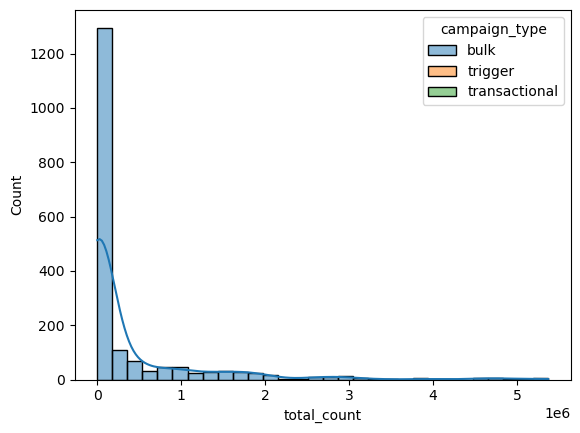

In [93]:
sns.histplot(data=campaigns_df, x="total_count", hue="campaign_type", bins=30, kde=True, multiple="stack")

In [109]:
campaigns_df['total_count'] = campaigns_df['total_count'].fillna(campaigns_df['total_count'].median())

In [111]:
print(campaigns_df["total_count"].describe())

count    1.907000e+03
mean     3.579332e+05
std      8.053851e+05
min      1.000000e+00
25%      8.865000e+02
50%      2.006500e+03
75%      2.495795e+05
max      5.371769e+06
Name: total_count, dtype: float64


### Work with 'Warmup_mode' column
Filling missing values in the 'warmup_mode' column with the most frequent value (mode).

In [34]:
campaigns_df['warmup_mode'] = campaigns_df['warmup_mode'].fillna(campaigns_df['warmup_mode'].mode()[0])
campaigns_df = campaigns_df.infer_objects(copy=False)

C:\Users\User\AppData\Local\Temp\ipykernel_15668\1786108946.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  campaigns_df['warmup_mode'] = campaigns_df['warmup_mode'].fillna(campaigns_df['warmup_mode'].mode()[0])


### Work with Subjects columns
'subject_length' = fill with 'median'
other subjects with  the most frequent value (mode).

In [37]:
campaigns_df['subject_length'] = campaigns_df['subject_length'].fillna(campaigns_df['subject_length'].median())

In [39]:
binary_cols = [
    'subject_with_personalization', 'subject_with_deadline', 'subject_with_emoji', 
    'subject_with_bonuses', 'subject_with_discount', 'subject_with_saleout'
]

for col in binary_cols:
    mode_value = campaigns_df[col].mode()[0]
    campaigns_df[col] = campaigns_df[col].fillna(mode_value)

campaigns_df = campaigns_df.infer_objects(copy=False)

C:\Users\User\AppData\Local\Temp\ipykernel_15668\2048126650.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  campaigns_df[col] = campaigns_df[col].fillna(mode_value)


### Work with 'start_at' and 'finished_at' columns

In [49]:
campaigns_df.isna().sum()

id                               0
campaign_type                    0
channel                          0
topic                            0
started_at                      83
finished_at                     99
total_count                      0
ab_test                          0
warmup_mode                      0
hour_limit                       0
subject_length                   0
subject_with_personalization     0
subject_with_deadline            0
subject_with_emoji               0
subject_with_bonuses             0
subject_with_discount            0
subject_with_saleout             0
is_test                          0
position                         0
dtype: int64